**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 4**
Exploración de datos

---

*   NOMBRE: Elda Estefanía Lara Cruz
*   MATRÍCULA: A01747420

En esta actividad trabajarás con el archivo `personal_loan.csv`, basado en un conjunto de datos sobre clientes bancarios y su comportamiento financiero disponible en Kaggle.

Los datos fueron recopilados para analizar la posibilidad de que los clientes acepten un préstamo personal y contienen información demográfica, financiera y de productos bancarios asociados. Los indicadores incluidos son:

* `ID`: Identificador único del cliente
* `Age`: Edad del cliente (años completos)
* `Experience`: Experiencia laboral en años
* `Income`: Ingreso anual del cliente (en miles de dólares. Por ejemplo, 60 = 60,000 USD/año)
* `ZIP Code`: Código postal del cliente
* `Family`: Número de miembros de la familia
* `CCAvg`: Promedio de gastos mensuales con tarjeta de crédito (en miles de dólares)
* `Education`: Nivel educativo (1 = graduado, 2 = universitario, 3 = posgrado)
* `Mortgage`: Monto de hipoteca que posee el cliente (en miles de dólares)
* `Securities Account`: Indicador de si tiene cuenta de valores (1 = sí, 0 = no)
* `CD Account`: Indicador de si tiene cuenta de certificado de depósito (1 = sí, 0 = no)
* `Online`: Indicador de si usa los servicios bancarios en línea (1 = sí, 0 = no)
* `CreditCard`: Indicador de si es titular de tarjeta de crédito (1 = sí, 0 = no)
* `Personal Loan`: Si el cliente aceptó (1) o no (0) un préstamo personal. Es la variable de salida o *target*, es decir, la que se pretende predecir más adelante al construir el modelo

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [1]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import norm

1. Descarga el archivo: `personal_loan.csv` y guarda, en un dataframe (`loan_df`), todos sus registros.
* Haz que la columna `ID` sea el índice del dataframe.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?

In [3]:
# Carga de datos con ID como índice
loan_df = pd.read_csv('/content/personal_loan.csv', index_col='ID')
n_inicial = len(loan_df)  # total de registros iniciales (se usa en la pregunta 2)
loan_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 5037 entries, 0 to 5036
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Age                 5037 non-null   int64  
 1   Experience          5037 non-null   int64  
 2   Income              5037 non-null   int64  
 3   ZIP Code            5037 non-null   int64  
 4   Family              5037 non-null   int64  
 5   CCAvg               5037 non-null   float64
 6   Education           5037 non-null   float64
 7   Mortgage            5037 non-null   int64  
 8   Personal Loan       5037 non-null   object 
 9   Securities Account  5037 non-null   object 
 10  CD Account          5037 non-null   object 
 11  Online              5037 non-null   object 
 12  CreditCard          5037 non-null   object 
dtypes: float64(2), int64(6), object(5)
memory usage: 550.9+ KB


**Respuesta.** El dataframe tiene 5,037 registros y 13 columnas (además del índice `ID`). Según `info()`, **8 columnas son numéricas** (`Age`, `Experience`, `Income`, `ZIP Code`, `Family`, `Education`, `Mortgage` de tipo entero o decimal, y `CCAvg`) y **5 son de texto** (`Personal Loan`, `Securities Account`, `CD Account`, `Online` y `CreditCard`). Que las cinco binarias aparezcan como texto ya anticipa que están almacenadas con formatos mezclados (se atiende en la pregunta 3).

# Limpieza

2. Obtén las estadísticas descriptivas de las variables numéricas y examina cuidadosamente los valores obtenidos de cada columna.
* Filtra el dataframe para visualizar los registros en que la edad supera los 100 años y elimínalos si no son pausibles.
* Analiza el resto de las variables y elimina aquellos registros que contengan valores inválidos o inconsistentes. Para cada acción que realices, justifica la decisión, explicando por qué consideras que el valor es incorrecto.
* ¿Cuántos registros se eliminaron (considerando todas las acciones de este ejercicio) y qué porcentaje representa respecto al total del dataframe inicial?

In [4]:
# Estadísticas descriptivas de las variables numéricas
loan_df.describe().round(2)

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage
count,5037.00,5037.00,5037.00,5037.00,5037.00,5037.00,5037.00,5037.00
mean,45.41,20.12,73.90,93152.87,2.39,1.94,1.88,56.50
std,11.65,11.46,46.13,2119.64,1.15,1.76,0.84,101.66
min,23.00,-3.00,8.00,9307.00,-3.00,0.00,1.00,0.00
25%,35.00,10.00,39.00,91911.00,1.00,0.70,1.00,0.00
50%,45.00,20.00,64.00,93437.00,2.00,1.50,2.00,0.00
75%,55.00,30.00,98.00,94608.00,3.00,2.60,3.00,101.00
max,144.00,43.00,224.00,96651.00,4.00,10.00,7.30,635.00


In [5]:
# Registros con edad mayor a 100 años
loan_df[loan_df['Age'] > 100]

,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
ID,,,,,,,,,,,,,
10,123,39,105,94710,4,2.4,3.0,0,0,0,0,No,0
250,144,6,29,94305,3,1.0,2.0,117,0,No,0,No,No
4800,130,7,73,94028,1,2.5,1.0,135,0,No,0,0,0


In [6]:
# Se eliminan por no ser plausibles
loan_df = loan_df[loan_df['Age'] <= 100]

In [7]:
# Búsqueda de valores inválidos o inconsistentes en el resto de las variables
invalidos = {
    'Experience < 0': loan_df['Experience'] < 0,
    'Family < 1': loan_df['Family'] < 1,
    'Education fuera de {1, 2, 3}': ~loan_df['Education'].isin([1, 2, 3]),
    'ZIP Code con menos de 5 dígitos': loan_df['ZIP Code'] < 10000,
}
for nombre, mascara in invalidos.items():
    print(f'{nombre}: {mascara.sum()} registros')

Experience < 0: 53 registros
Family < 1: 2 registros
Education fuera de {1, 2, 3}: 1 registros
ZIP Code con menos de 5 dígitos: 1 registros


In [8]:
# Se eliminan los registros con al menos una inconsistencia
hay_invalido = pd.concat(invalidos.values(), axis=1).any(axis=1)
loan_df = loan_df[~hay_invalido].copy()

eliminados = n_inicial - len(loan_df)
print(f'Registros eliminados: {eliminados} de {n_inicial} ({eliminados / n_inicial:.2%})')

Registros eliminados: 60 de 5037 (1.19%)


**Justificación de los registros eliminados.**

| Criterio | Registros | Por qué el valor es incorrecto |
|---|---|---|
| `Age` > 100 | 3 (edades de 123, 144 y 130 años) | No son plausibles para un cliente bancario activo, y además con `Experience` de 39, 6 y 7 años serían inconsistentes. |
| `Experience` < 0 | 53 (valores de -1, -2 y -3) | La experiencia laboral no puede ser negativa. Todos son clientes de entre 23 y 29 años, por lo que probablemente es un error de captura. |
| `Family` < 1 | 2 (valores de -3 y -1) | El número de miembros de la familia no puede ser negativo ni cero, ya que el cliente mismo cuenta como miembro. |
| `Education` fuera de {1, 2, 3} | 1 (valor de 7.3) | Es un valor decimal que no corresponde a ninguna categoría definida (1 = graduado, 2 = universitario, 3 = posgrado). |
| `ZIP Code` con menos de 5 dígitos | 1 (código 9307) | Los demás códigos postales tienen 5 dígitos (90000 a 96651); este tiene solo 4, por lo que está truncado o mal capturado. |

Las variables `Income` (8 a 224), `CCAvg` (0 a 10) y `Mortgage` (0 a 635) tienen rangos plausibles y no presentan valores negativos. Además, en todos los registros `Age` - `Experience` es de al menos 24 años, así que no hay casos en que la experiencia sea mayor que la edad posible.

**Total eliminado en esta pregunta: 60 registros de 5,037 (1.19 %).** Los criterios no se traslapan, por lo que 3 + 53 + 2 + 1 + 1 = 60.

3. Obtén las estadísticas descriptivas de las variables de texto e imprime las frecuencias de sus categorías.
* Algunas columnas almacenan valores binarios utilizando distintos formatos. Unifica estos valores de manera consistente, asegurándote de que coincidan con la descripción de las variables al inicio de esta libreta.

In [9]:
# Estadísticas y frecuencias de las variables de texto
txt_cols = loan_df.select_dtypes(exclude='number').columns
display(loan_df[txt_cols].describe())
for col in txt_cols:
    print(loan_df[col].value_counts(), '\n')

,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4977,4977,4977,4977,4977
unique,4,4,4,4,4
top,0,No,No,Yes,0
freq,3475,2693,2462,1700,2628


Personal Loan
0      3475
No     1017
Yes     368
1       117
Name: count, dtype: int64 

Securities Account
No     2693
0      1765
Yes     390
1       129
Name: count, dtype: int64 

CD Account
No     2462
0      2212
1       163
Yes     140
Name: count, dtype: int64 

Online
Yes    1700
No     1628
1      1275
0       374
Name: count, dtype: int64 

CreditCard
0      2628
Yes     907
No      885
1       557
Name: count, dtype: int64 



In [10]:
# Unificación de los valores binarios: Yes/1 -> 1 y No/0 -> 0
mapa_binario = {'Yes': 1, 'No': 0, '1': 1, '0': 0}
for col in txt_cols:
    loan_df[col] = loan_df[col].map(mapa_binario).astype(int)

for col in txt_cols:
    print(loan_df[col].value_counts(), '\n')

Personal Loan
0    4492
1     485
Name: count, dtype: int64 

Securities Account
0    4458
1     519
Name: count, dtype: int64 

CD Account
0    4674
1     303
Name: count, dtype: int64 

Online
1    2975
0    2002
Name: count, dtype: int64 

CreditCard
0    3513
1    1464
Name: count, dtype: int64 



**Respuesta.** Las cinco variables de texto tenían 4 valores únicos cada una, porque el mismo concepto binario estaba capturado con dos formatos distintos: `Yes`/`No` y `1`/`0` (como texto). Se unificaron con `Yes` → 1 y `No` → 0, de modo que coincidan con la descripción de la libreta (1 = sí, 0 = no). Tras la unificación cada variable tiene solo 2 categorías. Por ejemplo, `Personal Loan` pasó de 4 valores (`0`, `No`, `Yes`, `1`) a 4,492 ceros y 485 unos, es decir, un 9.7 % de clientes que aceptaron el préstamo.

4. Verifica si hay registros duplicados y si fuera así, elimínalos del dataframe.
* Asegúrate de reiniciar el índice para mantener una secuencia continua tras todas las eliminaciones de registros que hasta este punto se han realizado.

In [11]:
# Verificación y eliminación de duplicados (se ignora el índice, que ya no es ID)
print(f'Registros duplicados: {loan_df.duplicated().sum()}')
loan_df = loan_df.drop_duplicates()

# Reinicio del índice
loan_df = loan_df.reset_index(drop=True)
print(f'Registros restantes: {len(loan_df)}')
loan_df.index

Registros duplicados: 36
Registros restantes: 4941


RangeIndex(start=0, stop=4941, step=1)

**Respuesta.** Se encontraron **36 registros duplicados** (filas idénticas en todas las columnas, salvo el `ID`, que ya era el índice) y se eliminaron conservando la primera aparición. La unificación de formatos de la pregunta 3 era necesaria antes de este paso, ya que un mismo cliente capturado como `Yes` en un registro y como `1` en otro no se habría detectado como duplicado. El índice se reinició con `reset_index(drop=True)` y ahora es continuo de 0 a 4,940.

En total, considerando las preguntas 2 y 4, se eliminaron 96 registros (1.91 % de los 5,037 iniciales) y el dataframe quedó con **4,941 registros**.

5. Aunque hasta ahora se han considerado los tipos de datos inferidos por pandas, antes del EDA es recomendable revisar la naturaleza estadística de cada variable (continua, discreta, categórica, binaria, etc.) para aplicar el análisis adecuado.

* Efectúa las siguientes conversiones:
  - Nominal: ZIP Code - `object`
  - Ordinal: Education - `category` con orden 1, 2, 3
  - Binarias: Personal Loan, Securities Account, CD Account, Online, CreditCard - `category`
* Crea dos listas llamadas `num_cols` y `cat_cols` que contengan los nombres de las variables numéricas (int64, float64) y categóricas (object, category) del dataset, respectivamente.

In [12]:
# Conversiones según la naturaleza estadística de cada variable
loan_df['ZIP Code'] = loan_df['ZIP Code'].astype(str).astype(object)
loan_df['Education'] = pd.Categorical(loan_df['Education'].astype(int),
                                      categories=[1, 2, 3], ordered=True)
bin_cols = ['Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']
for col in bin_cols:
    loan_df[col] = loan_df[col].astype('category')

num_cols = loan_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = loan_df.select_dtypes(include=['object', 'category']).columns.tolist()
print('num_cols:', num_cols)
print('cat_cols:', cat_cols)
loan_df.dtypes

num_cols: ['Age', 'Experience', 'Income', 'Family', 'CCAvg', 'Mortgage']
cat_cols: ['ZIP Code', 'Education', 'Personal Loan', 'Securities Account', 'CD Account', 'Online', 'CreditCard']


,0
Age,int64
Experience,int64
Income,int64
ZIP Code,object
Family,int64
CCAvg,float64
Education,category
Mortgage,int64
Personal Loan,category
Securities Account,category


**Respuesta.** Se convirtieron `ZIP Code` a `object` (es un identificador nominal: no tiene sentido sumarlo ni promediarlo), `Education` a `category` ordenada (1 < 2 < 3) y las cinco variables binarias a `category`. Las listas quedaron así:

* `num_cols`: `Age`, `Experience`, `Income`, `Family`, `CCAvg`, `Mortgage`.
* `cat_cols`: `ZIP Code`, `Education`, `Personal Loan`, `Securities Account`, `CD Account`, `Online`, `CreditCard`.

# Análisis exploratorio de datos (univariado)

6. Para el análisis de las variables numéricas obtén nuevamente las estadísticas descriptivas incluyendo los valores de simetría y curtosis.
* Clasifica las variables `Age`, `Income` y `Mortgage` según los valores observados de asimetría y curtosis.

In [13]:
# Estadísticas descriptivas con asimetría y curtosis (exceso de curtosis, normal = 0)
desc = loan_df[num_cols].describe().T
desc['skew'] = loan_df[num_cols].skew()
desc['kurtosis'] = loan_df[num_cols].kurt()
desc.round(3)

,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
Age,4941.0,45.560,11.316,24.0,36.0,46.0,55.0,67.0,-0.023,-1.162
Experience,4941.0,20.335,11.308,0.0,11.0,20.0,30.0,43.0,-0.015,-1.135
Income,4941.0,73.827,46.107,8.0,39.0,64.0,98.0,224.0,0.842,-0.046
Family,4941.0,2.392,1.148,1.0,1.0,2.0,3.0,4.0,0.159,-1.404
CCAvg,4941.0,1.936,1.748,0.0,0.7,1.5,2.6,10.0,1.595,2.636
Mortgage,4941.0,56.664,101.875,0.0,0.0,0.0,101.0,635.0,2.104,4.760


**Clasificación de las variables** (asimetría: |skew| < 0.5 simétrica, 0.5 a 1 moderada, > 1 fuerte; la curtosis es el exceso de curtosis, donde 0 equivale a una distribución normal):

| Variable | Asimetría | Curtosis | Clasificación |
|---|---|---|---|
| `Age` | -0.02 | -1.16 | Simétrica y **platicúrtica** (más plana que la normal, colas ligeras). |
| `Income` | 0.84 | -0.05 | Asimetría **positiva moderada** (cola larga a la derecha) y **mesocúrtica** (curtosis similar a la normal). |
| `Mortgage` | 2.10 | 4.76 | Asimetría **positiva fuerte** y **leptocúrtica** (pico muy marcado y colas pesadas). |

7. Genera un histograma para cada variable numérica, incluyendo la curva KDE y la curva de una distribución normal como referencia.
* Para las variables que clasificaste antes, compara los histogramas generados con los valores numéricos calculados y comenta si la forma de cada distribución coincide con lo esperado.
* Para cada variable, crea un gráfico de boxplot individual que incluya la media.
* Analiza la posición de la media respecto a la mediana. ¿Qué indica esta relación sobre el sesgo (asimetría) de la distribución?

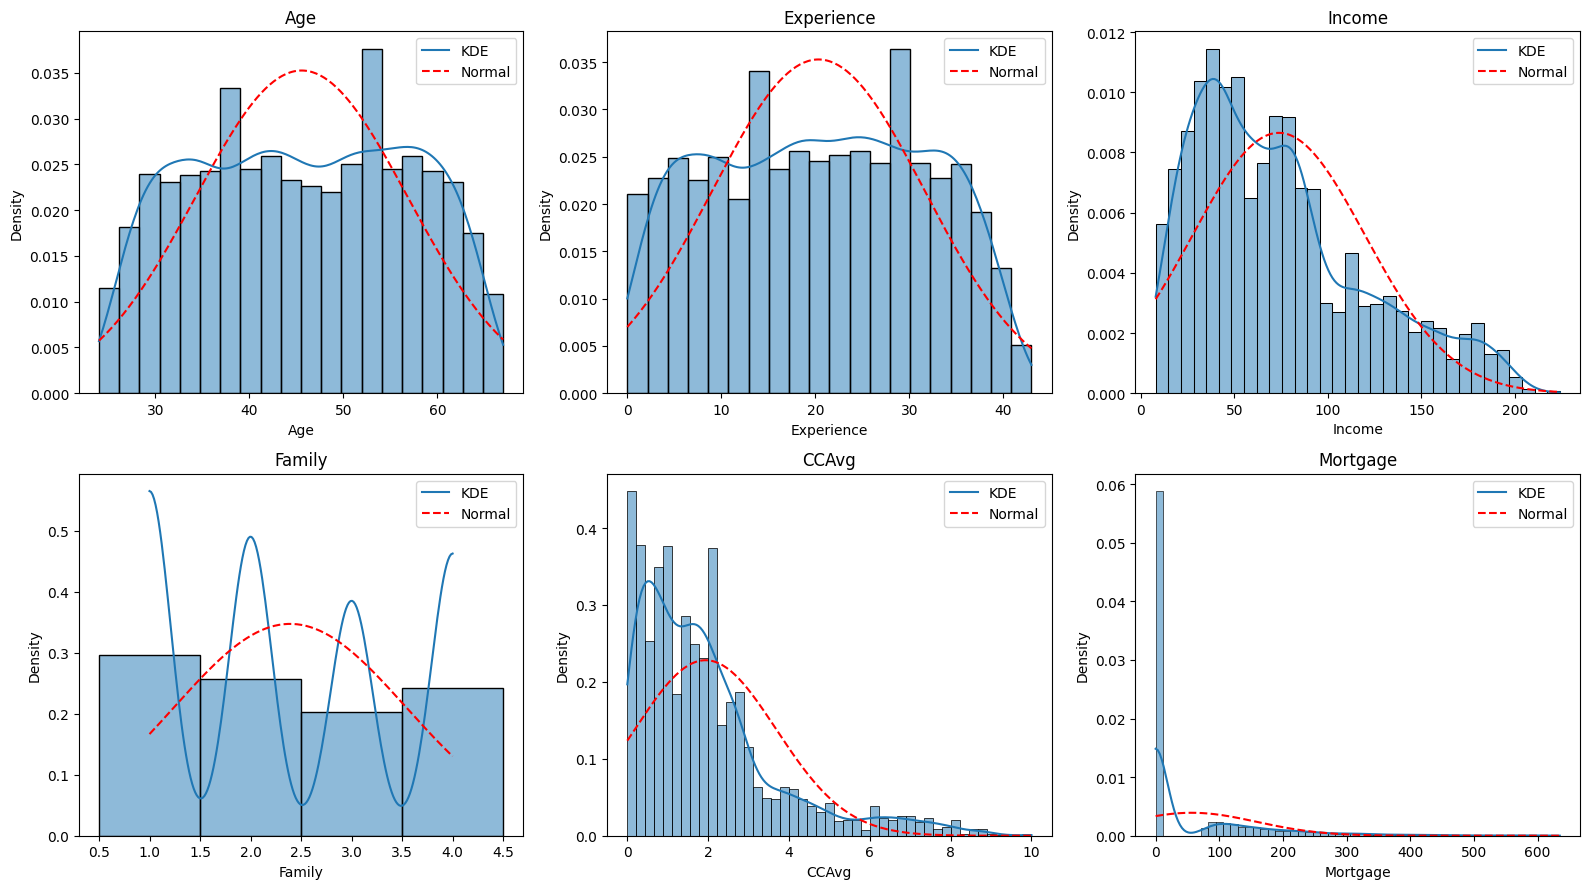

In [14]:
# Histogramas con KDE y curva normal de referencia
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(loan_df[col], kde=True, stat='density', discrete=(col == 'Family'),
                 line_kws={'label': 'KDE'}, ax=ax)
    x = np.linspace(loan_df[col].min(), loan_df[col].max(), 200)
    ax.plot(x, norm.pdf(x, loan_df[col].mean(), loan_df[col].std()),
            color='red', linestyle='--', label='Normal')
    ax.set_title(col)
    ax.legend()
plt.tight_layout()
plt.show()

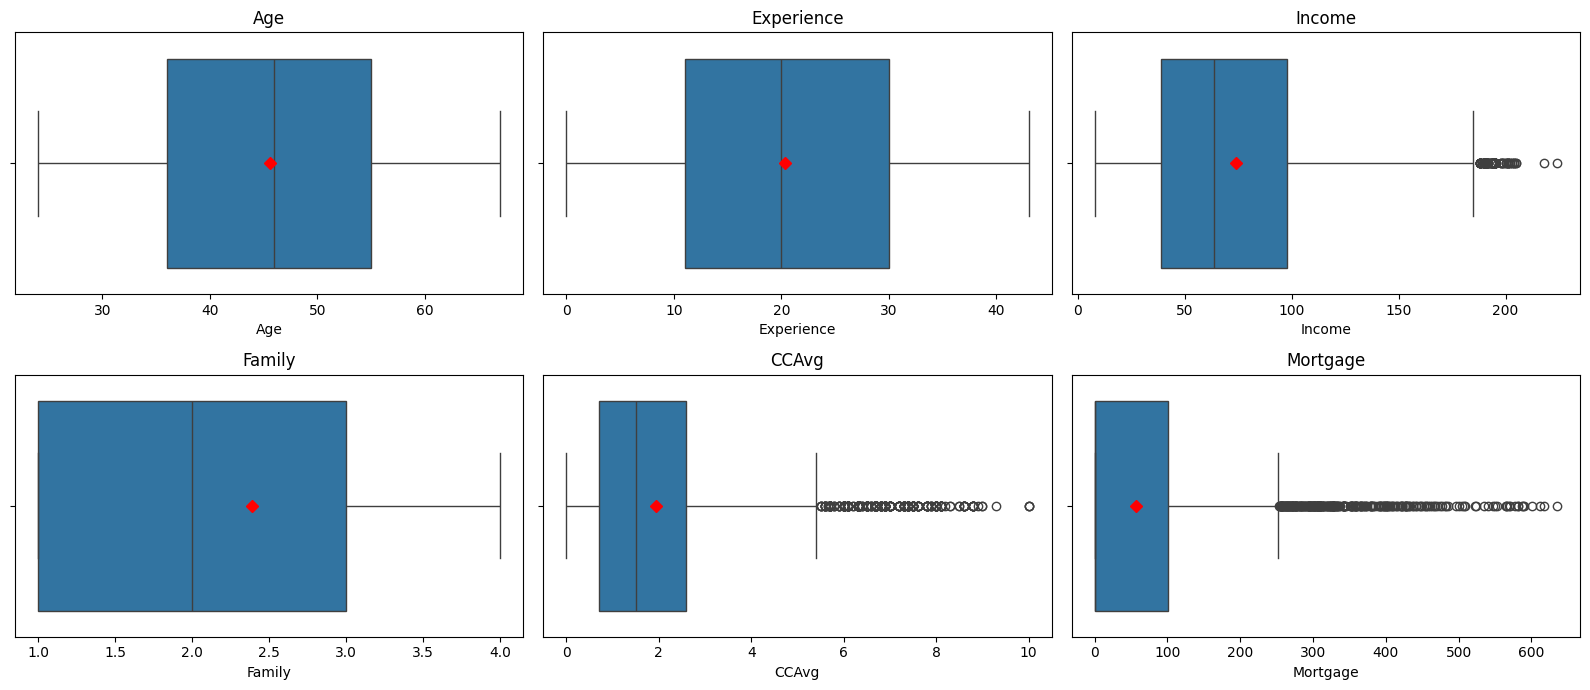

In [15]:
# Boxplots individuales con la media (rombo rojo)
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x=loan_df[col], showmeans=True,
                meanprops={'marker': 'D', 'markerfacecolor': 'red', 'markeredgecolor': 'red'},
                ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [16]:
# Media vs. mediana
pd.DataFrame({'media': loan_df[num_cols].mean(),
              'mediana': loan_df[num_cols].median(),
              'media - mediana': loan_df[num_cols].mean() - loan_df[num_cols].median(),
              'skew': loan_df[num_cols].skew()}).round(3)

,media,mediana,media - mediana,skew
Age,45.560,46.0,-0.440,-0.023
Experience,20.335,20.0,0.335,-0.015
Income,73.827,64.0,9.827,0.842
Family,2.392,2.0,0.392,0.159
CCAvg,1.936,1.5,0.436,1.595
Mortgage,56.664,0.0,56.664,2.104


**Comparación de los histogramas con los valores numéricos.**

* **`Age`:** el histograma es casi plano, con una densidad parecida entre los 30 y los 60 años, lo que concuerda con la asimetría cercana a cero (simétrica) y con la curtosis negativa (platicúrtica). Aunque es simétrica, **no sigue una normal**: la curva roja tiene un pico central que los datos no muestran. `Experience` se comporta de forma casi idéntica.
* **`Income`:** la mayor concentración está entre 30 y 80 mil dólares, con una cola larga hacia la derecha hasta 224. Esto coincide con la asimetría positiva moderada (0.84). La curtosis cercana a 0 también concuerda: el pico no es especialmente alto ni las colas son más pesadas que las de la normal, pero la forma sigue sin ser normal por el sesgo.
* **`Mortgage`:** hay un pico enorme en 0 (la mayoría de los clientes no tiene hipoteca) y una cola muy larga hasta 635. Coincide con la asimetría fuerte (2.10) y la curtosis alta (4.76): la curva normal queda completamente por debajo del pico real.
* En el resto de las variables, `CCAvg` también tiene asimetría positiva (1.60, curtosis 2.64) y `Family` es discreta con valores de 1 a 4 casi uniformes, por lo que la normal no es una buena referencia.

**Boxplots y posición de la media respecto a la mediana.** En los boxplots (rombo rojo = media) se observa que `Age`, `Experience` y `Family` no presentan valores atípicos, mientras que `Income`, `CCAvg` y `Mortgage` tienen numerosos puntos atípicos del lado derecho, lo que es consistente con su asimetría positiva.

* Cuando la distribución es simétrica, la media y la mediana casi coinciden: `Age` (45.6 vs. 46) y `Experience` (20.3 vs. 20).
* Cuando la media es **mayor** que la mediana, indica asimetría positiva, ya que los valores extremos altos jalan la media hacia la derecha: `Income` (73.8 vs. 64), `CCAvg` (1.94 vs. 1.5) y sobre todo `Mortgage` (56.7 vs. 0).
* Por lo tanto, la relación entre media y mediana coincide con el signo y la magnitud de la asimetría calculada. Para variables con sesgo, la mediana resume mejor el valor típico que la media.

8. Obtén las estadísticas descriptivas de las variables categóricas.
* Genera un gráfico de barras para cada variable. En las de alta cardinalidad, sólo incluye los 10 valores más relevantes.

In [17]:
# Estadísticas descriptivas de las variables categóricas
loan_df[cat_cols].describe()

,ZIP Code,Education,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,4941,4941,4941,4941,4941,4941,4941
unique,467,3,2,2,2,2,2
top,94720,1,0,0,0,1,0
freq,163,2079,4462,4426,4640,2951,3489


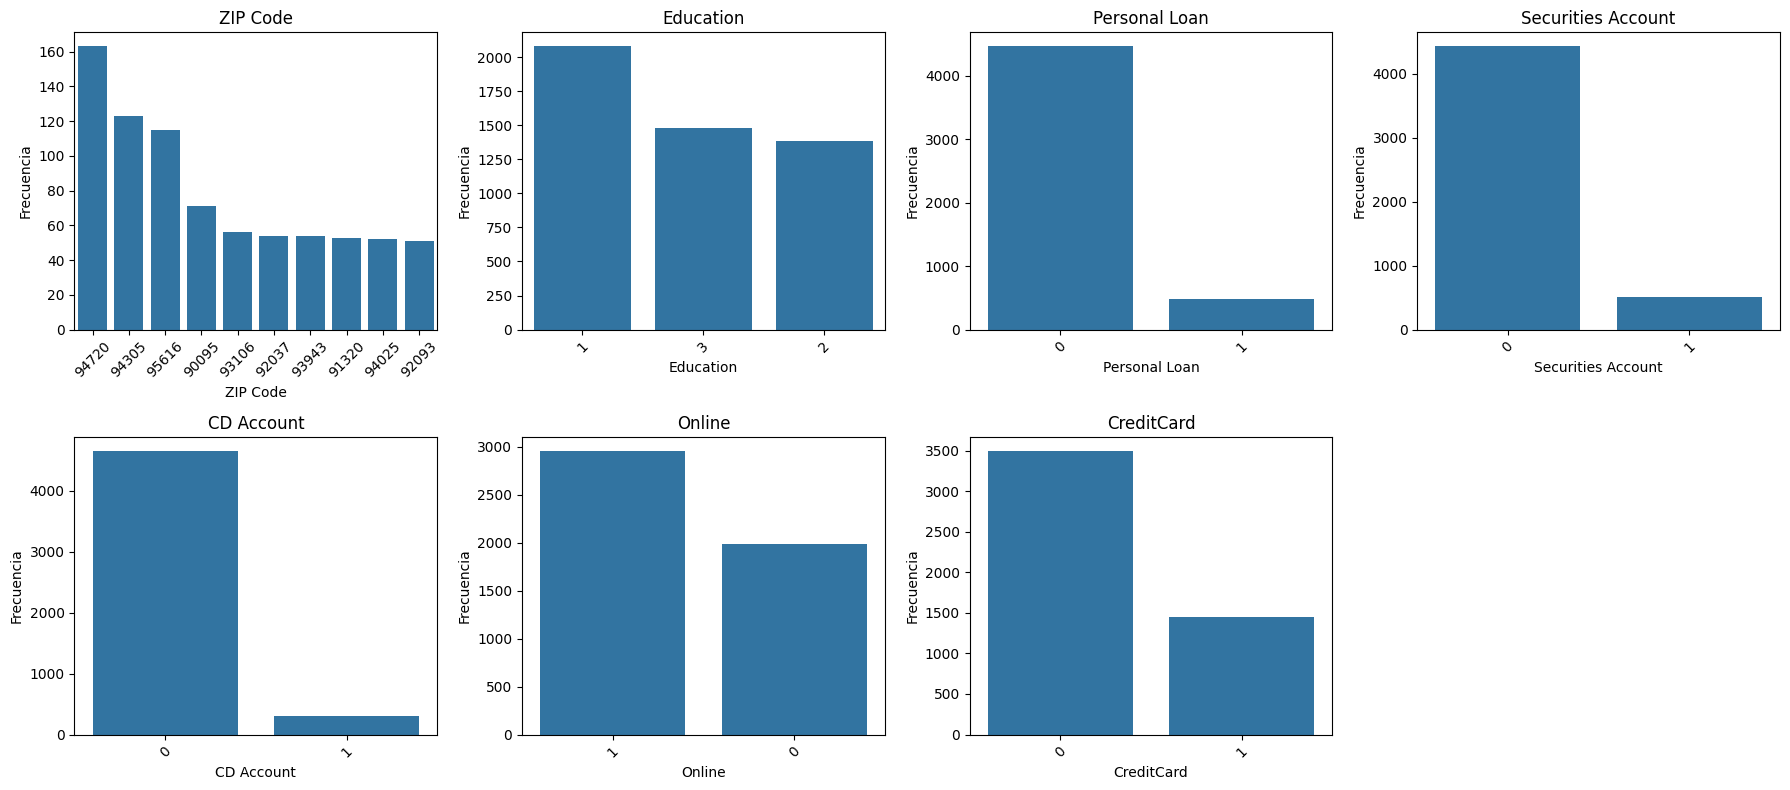

In [18]:
# Gráficos de barras (máximo los 10 valores más frecuentes)
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flat, cat_cols):
    top = loan_df[col].value_counts().head(10)
    sns.barplot(x=top.index.astype(str), y=top.values, ax=ax)
    ax.set_title(col)
    ax.set_ylabel('Frecuencia')
    ax.tick_params(axis='x', rotation=45)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

**Respuesta.** `ZIP Code` es la única variable de alta cardinalidad: tiene 467 valores distintos y el más frecuente es 94720 (163 registros), por eso se graficaron solo los 10 más frecuentes. `Education` tiene 3 categorías y la más común es 1 (graduado, 2,079 clientes). Las variables binarias están desbalanceadas: la clase 0 domina en `Personal Loan` (4,462 de 4,941; solo ~9.7 % aceptó el préstamo), `Securities Account` y `CD Account`, además de `CreditCard` (3,489 sin tarjeta); en cambio, en `Online` predomina el valor 1 (2,951 clientes usan la banca en línea). Este desbalance en la variable de salida es relevante para el modelo que se construirá más adelante.

# Análisis exploratorio de datos (bivariado)

9. Obtén la matriz de gráficos de dispersión (*scatter matrix*) de todas las variables numéricas.
* Observa las relaciones entre las variables, selecciona un par representativo y describe los patrones o tendencias que sean evidentes.
* Para cuantificar la fuerza y dirección de las relaciones observadas, genera un mapa de calor con los valores de correlación de *Pearson*. ¿El valor numérico obtenido del par seleccionado se corresponde con lo esperado?

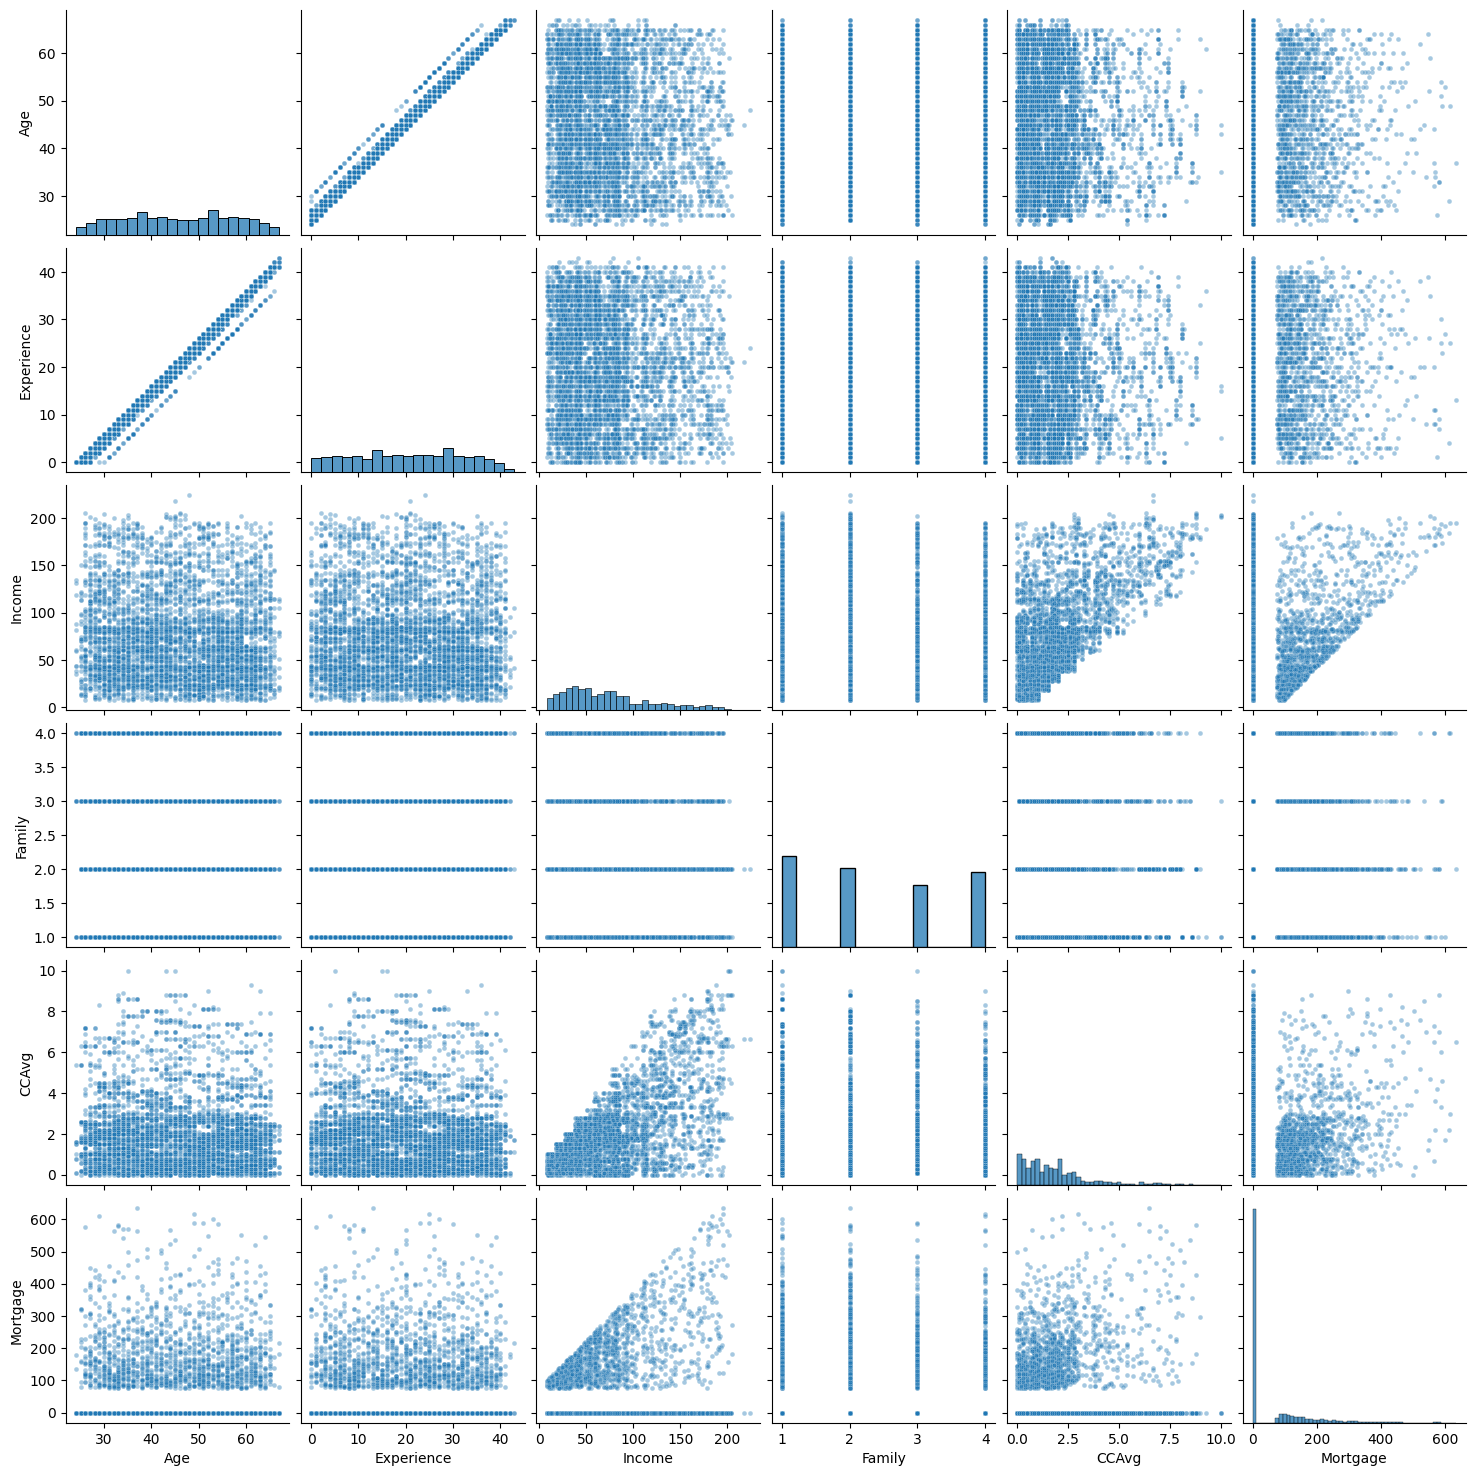

In [19]:
# Matriz de gráficos de dispersión
sns.pairplot(loan_df[num_cols], plot_kws={'alpha': 0.4, 's': 12})
plt.show()

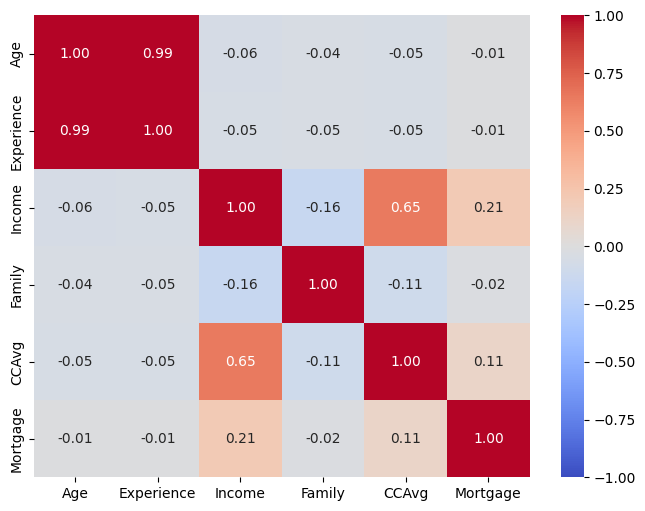

In [20]:
# Mapa de calor de correlación de Pearson
plt.figure(figsize=(8, 6))
sns.heatmap(loan_df[num_cols].corr(method='pearson'), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1)
plt.show()

**Par seleccionado: `Age` y `Experience`.** En la matriz de dispersión forman una banda diagonal muy estrecha y ascendente: a mayor edad, mayor experiencia laboral, de forma casi lineal (cada año de edad suma aproximadamente un año de experiencia). Es la relación más evidente de todo el conjunto. Otras relaciones visibles son `Income` con `CCAvg` (positiva en forma de abanico: a mayor ingreso, mayor gasto con tarjeta y más dispersión) e `Income` con `Mortgage` (las hipotecas altas solo aparecen en ingresos altos).

**Correlación de Pearson.** El mapa de calor muestra una correlación de aproximadamente **0.99** entre `Age` y `Experience`, que corresponde con lo esperado por la gráfica: una relación lineal positiva casi perfecta. Esto también significa que ambas variables aportan prácticamente la misma información (multicolinealidad), algo a considerar en el modelo. Las demás correlaciones fuertes son moderadas: `Income`-`CCAvg` (≈ 0.65) e `Income`-`Mortgage` (≈ 0.21, débil, porque muchos clientes sin hipoteca aplanan la relación); el resto son cercanas a 0.

10. Realiza un análisis de todas las variables del dataset con respecto a la variable de salida `Personal Loan`.
* Variables numéricas: Genera box plots para comparar la distribución de cada variable según los valores de `Personal Loan`.
* Variables categóricas (sin considerar `ZIP Code`): Genera gráficos de barras apiladas que muestren la distribución relativa de `Personal Loan` dentro de cada categoría de la variable.
* Para cada grupo de variables (numéricas y categóricas), comenta al menos un hallazgo o patrón relevante observado en los gráficos generados.


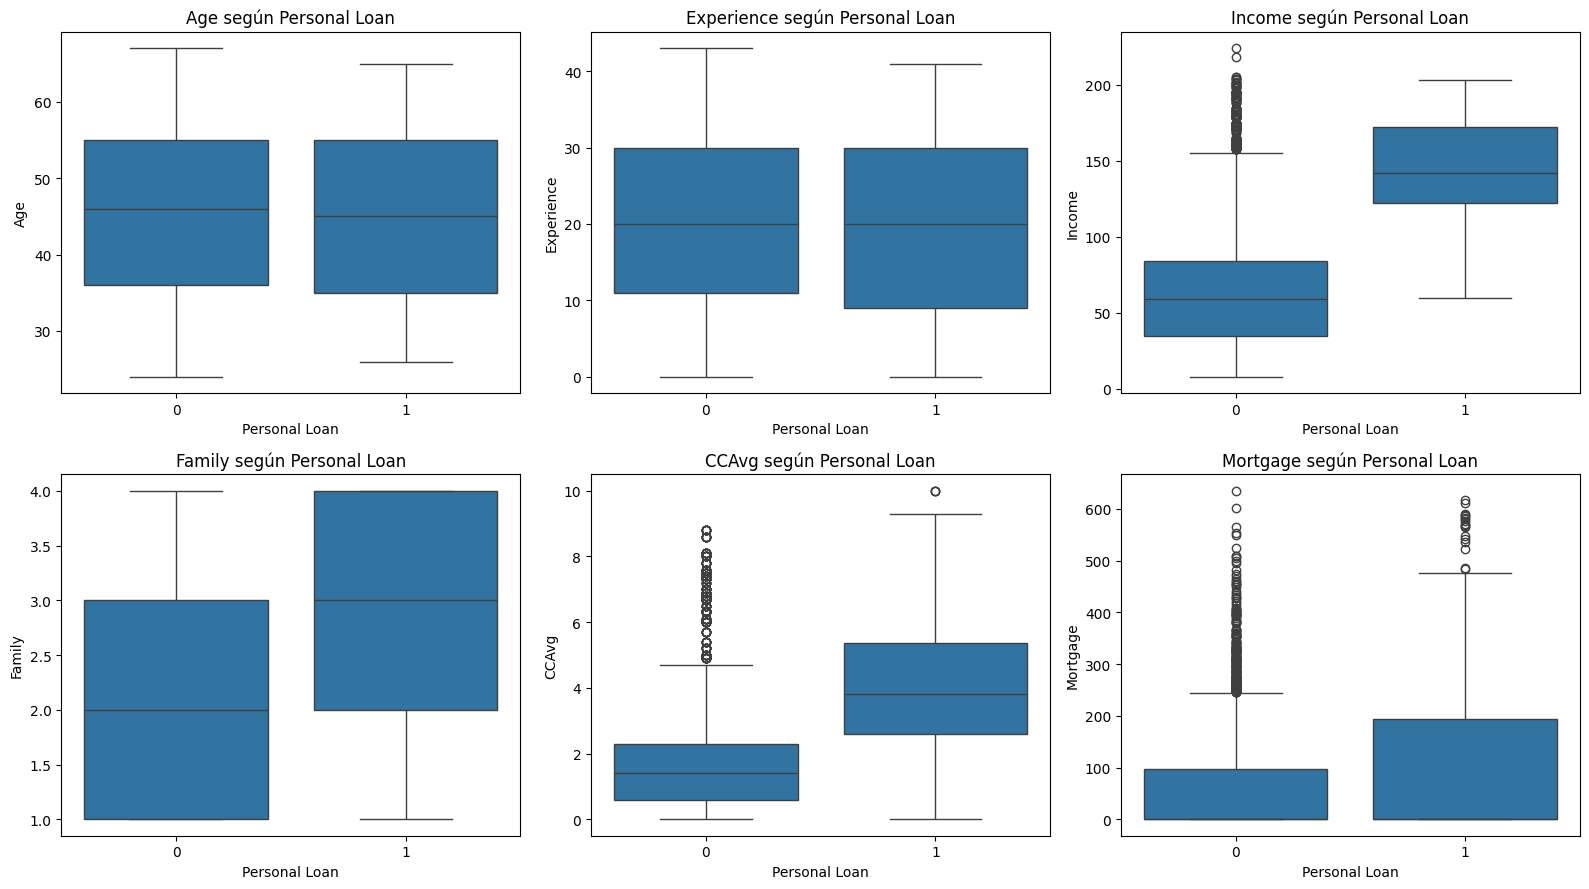

,Age,Experience,Income,Family,CCAvg,Mortgage
Personal Loan,,,,,,
0,46.0,20.0,59.0,2.0,1.4,0.0
1,45.0,20.0,142.0,3.0,3.8,0.0


In [21]:
# Variables numéricas vs. Personal Loan
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x='Personal Loan', y=col, data=loan_df, ax=ax)
    ax.set_title(f'{col} según Personal Loan')
plt.tight_layout()
plt.show()

loan_df.groupby('Personal Loan', observed=True)[num_cols].median()

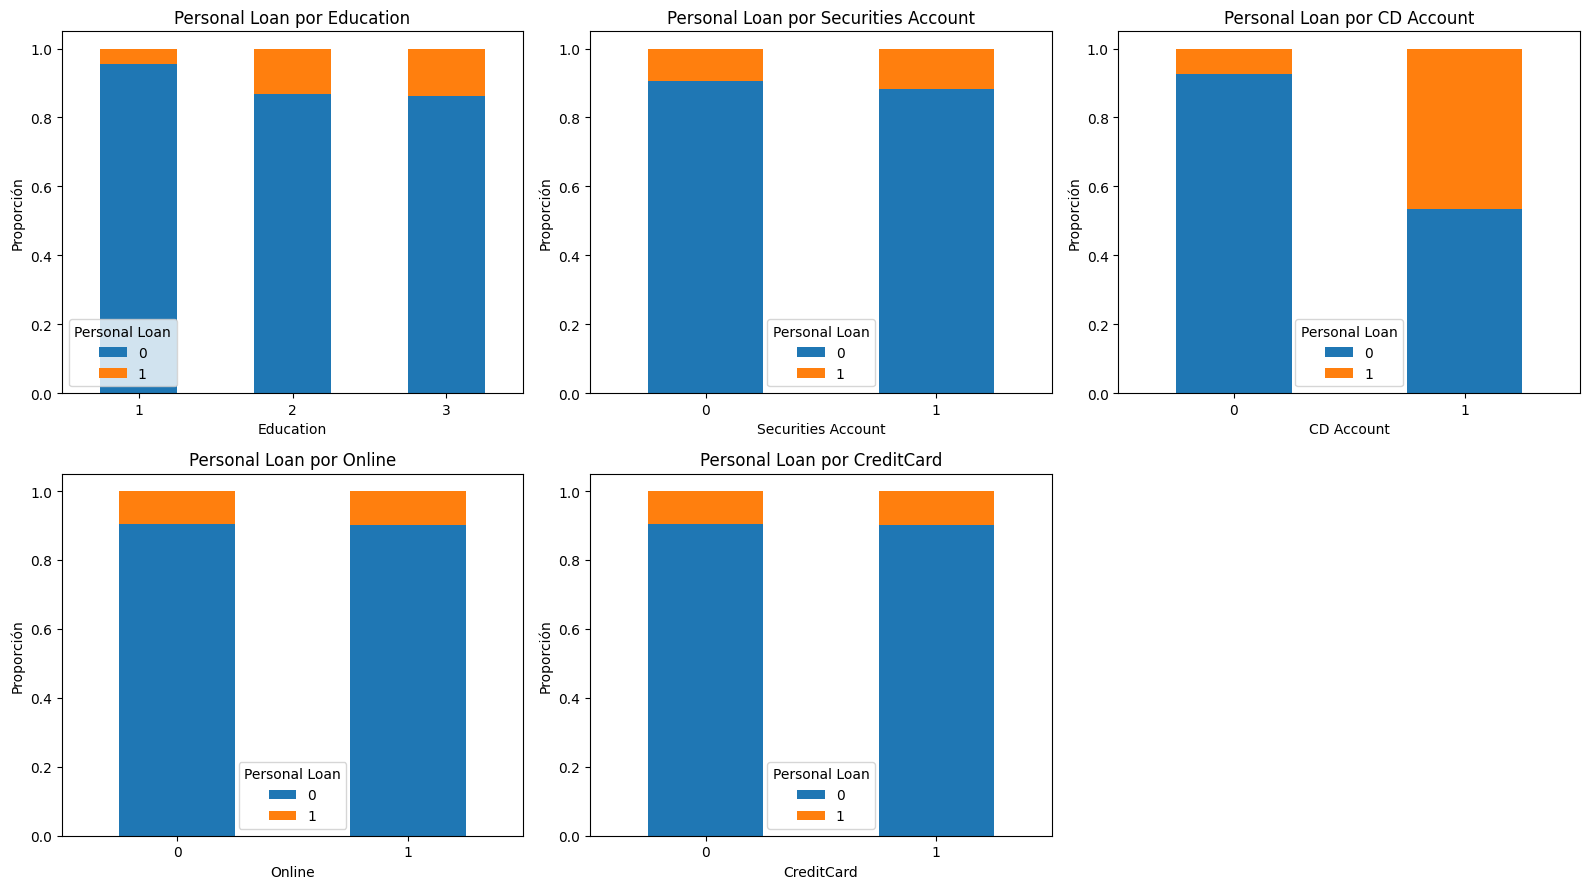

Personal Loan      0      1
Education                  
1              0.955  0.045
2              0.869  0.131
3              0.861  0.139 

Personal Loan           0      1
Securities Account              
0                   0.905  0.095
1                   0.883  0.117 

Personal Loan      0      1
CD Account                 
0              0.927  0.073
1              0.535  0.465 

Personal Loan      0      1
Online                     
0              0.906  0.094
1              0.901  0.099 

Personal Loan      0      1
CreditCard                 
0              0.904  0.096
1              0.902  0.098 



In [22]:
# Variables categóricas (sin ZIP Code) vs. Personal Loan: proporción dentro de cada categoría
cat_vs_loan = [c for c in cat_cols if c not in ('ZIP Code', 'Personal Loan')]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, cat_vs_loan):
    prop = pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index')
    prop.plot(kind='bar', stacked=True, ax=ax, rot=0)
    ax.set_title(f'Personal Loan por {col}')
    ax.set_ylabel('Proporción')
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

for col in cat_vs_loan:
    print(pd.crosstab(loan_df[col], loan_df['Personal Loan'], normalize='index').round(3), '\n')

**Hallazgos en variables numéricas.** `Income` y `CCAvg` son las que mejor separan a los dos grupos: los clientes que aceptaron el préstamo tienen una mediana de ingreso de 142 mil dólares frente a 59 mil de quienes no lo aceptaron, y una mediana de gasto mensual con tarjeta de 3.8 frente a 1.4 mil dólares. `Family` tiene una diferencia más pequeña (mediana de 3 vs. 2 miembros). `Age` y `Experience` casi no distinguen (medianas de 45 vs. 46 y 20 vs. 20), por lo que la edad no parece influir en la aceptación.

**Hallazgos en variables categóricas.** La más relevante es `CD Account`: el 46.5 % de los clientes con cuenta de certificado de depósito aceptó el préstamo, contra solo 7.3 % entre quienes no la tienen. `Education` también marca diferencia: aceptan 4.5 % de los clientes con nivel 1 frente a 13.1 % (nivel 2) y 13.9 % (nivel 3). En cambio, `Online` (9.9 % vs. 9.4 %), `CreditCard` (9.8 % vs. 9.6 %) y, en menor medida, `Securities Account` (11.7 % vs. 9.5 %) muestran proporciones casi iguales entre categorías, por lo que parecen aportar poca información para distinguir a quienes aceptan el préstamo.

---

**Declaración de uso de IA**

Anthropic. (2026). *Claude (Claude Sonnet 5.5)* [Modelo de lenguaje grande], utilizado para generación de código y redacción preliminar de los análisis. https://claude.ai/

---